# Results

Every number in the README, computed from the saved run artifacts rather than transcribed.

The three findings this project actually turns on are not the headline scores:

1. **The classifier was never the bottleneck** — event F1 rose 0.504 → 0.796 while window
   AUPRC moved 0.712 → 0.721.
2. **Which architecture wins depends on the metric** — the U-Net beats the feature
   pipeline decisively at sample level, ties at event level, and is worse for seizure burden.
3. **Hand-crafted features were the brittle ones** — they collapsed on the held-out test
   split, and the cause is measurable.

All logic is imported from `src/mouse_seizure/`; this notebook contains narrative and figures.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy import stats

from mouse_seizure.config import project_root

A = project_root() / "artifacts"

SIG, EMB = "#2a78d6", "#c25219"
INK, MUTED, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e5e4e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "figure.dpi": 110, "lines.linewidth": 1.6,
})

def load(path):
    return pl.read_parquet(A / path)

def mean_of(frame, column):
    v = frame[column].to_numpy()
    return float(v[np.isfinite(v)].mean())

## 1. The classifier was never the bottleneck

Phase 1 ran the complete chain with a deliberately minimal model and no tuning. Phase 2
changed two things: it trained on the natural class prior so the probabilities mean
something, and it chose the decision threshold on a held-out animal.

The classifier barely moved. The event-level result nearly doubled.

In [2]:
p1 = load("phase1/loao_results.parquet")
p2 = load("phase2/results_without_artifact.parquet")

rows = []
for name, frame in (("Phase 1 (untuned)", p1), ("Phase 2 (tuned)", p2)):
    rows.append({
        "stage": name,
        "event F1": round(mean_of(frame, "event_f1"), 3),
        "window AUPRC": round(mean_of(frame, "window_auprc"), 3),
        "false alarms/h": round(mean_of(frame, "false_alarms_per_hour"), 2),
        "burden bias": round(
            float(np.nanmean(frame["burden_pred"].to_numpy() - frame["burden_true"].to_numpy())), 1
        ),
    })
print(pl.DataFrame(rows))

shape: (2, 5)
┌───────────────────┬──────────┬──────────────┬────────────────┬─────────────┐
│ stage             ┆ event F1 ┆ window AUPRC ┆ false alarms/h ┆ burden bias │
│ ---               ┆ ---      ┆ ---          ┆ ---            ┆ ---         │
│ str               ┆ f64      ┆ f64          ┆ f64            ┆ f64         │
╞═══════════════════╪══════════╪══════════════╪════════════════╪═════════════╡
│ Phase 1 (untuned) ┆ 0.504    ┆ 0.712        ┆ 44.6           ┆ 43.9        │
│ Phase 2 (tuned)   ┆ 0.796    ┆ 0.716        ┆ 4.31           ┆ 0.8         │
└───────────────────┴──────────┴──────────────┴────────────────┴─────────────┘


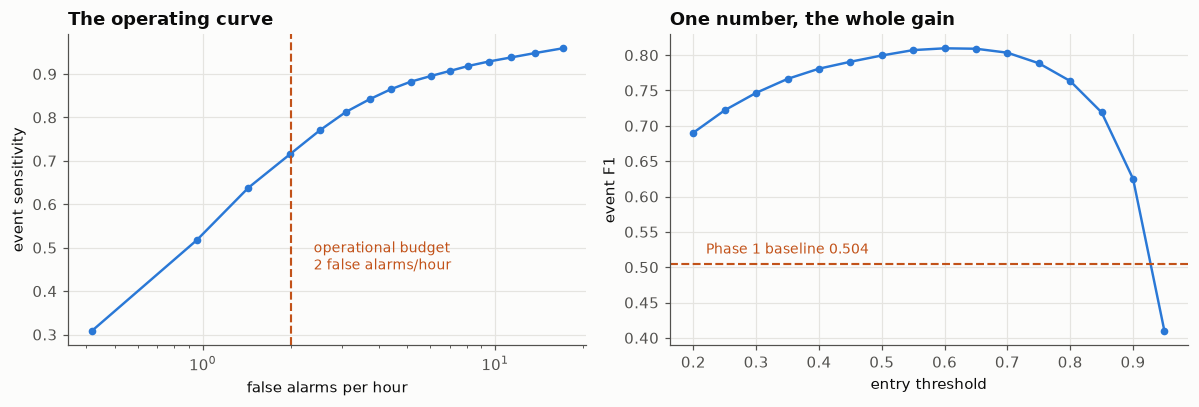

In [3]:
curve = (
    load("phase2/curve_full.parquet")
    .group_by("high")
    .agg(
        pl.col("event_f1").drop_nans().mean(),
        pl.col("false_alarms_per_hour").drop_nans().mean(),
        pl.col("event_sensitivity").drop_nans().mean(),
        pl.col("event_precision").drop_nans().mean(),
    )
    .sort("high")
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].plot(curve["false_alarms_per_hour"], curve["event_sensitivity"],
             color=SIG, marker="o", markersize=4)
axes[0].axvline(2.0, color=EMB, linestyle="--", linewidth=1.4)
axes[0].text(2.4, 0.45, "operational budget\n2 false alarms/hour", color=EMB, fontsize=9)
axes[0].set_xlabel("false alarms per hour")
axes[0].set_ylabel("event sensitivity")
axes[0].set_title("The operating curve", loc="left", fontweight="bold")
axes[0].set_xscale("log")

axes[1].plot(curve["high"], curve["event_f1"], color=SIG, marker="o", markersize=4,
             label="event F1")
axes[1].axhline(mean_of(p1, "event_f1"), color=EMB, linestyle="--", linewidth=1.4)
axes[1].text(0.22, mean_of(p1, "event_f1") + 0.015,
             f"Phase 1 baseline {mean_of(p1, 'event_f1'):.3f}", color=EMB, fontsize=9)
axes[1].set_xlabel("entry threshold")
axes[1].set_ylabel("event F1")
axes[1].set_title("One number, the whole gain", loc="left", fontweight="bold")

plt.tight_layout()
plt.show()

The right panel is the project's central claim in one line. **The model is identical at
every point on it.** Only the threshold changes, and it spans most of the distance between
the untuned baseline and the final result.

This is why no effort was spent tuning CatBoost. A better classifier moves window AUPRC;
the operating point moves the number anyone cares about.

## 2. Per-animal variance is the honest story

Eight animals means eight folds, and a mean alone hides how much they disagree. Fold spread
(±0.125) is larger than most of the differences measured later, which is why every
comparison below uses a paired test rather than comparing means.

In [4]:
unet = load("phase3/results_unet.parquet")
per_animal = (
    p2.group_by("mouse").agg(pl.col("event_f1").mean().alias("features"))
    .join(unet.group_by("mouse").agg(pl.col("event_f1").mean().alias("unet")), on="mouse")
    .sort("mouse")
)
print(per_animal.with_columns(
    (pl.col("unet") - pl.col("features")).round(3).alias("delta")
).with_columns(pl.col("features").round(3), pl.col("unet").round(3)))

shape: (8, 4)
┌──────────┬──────────┬───────┬────────┐
│ mouse    ┆ features ┆ unet  ┆ delta  │
│ ---      ┆ ---      ┆ ---   ┆ ---    │
│ str      ┆ f64      ┆ f64   ┆ f64    │
╞══════════╪══════════╪═══════╪════════╡
│ train_M1 ┆ 0.781    ┆ 0.91  ┆ 0.13   │
│ train_M2 ┆ 0.719    ┆ 0.714 ┆ -0.005 │
│ train_M3 ┆ 0.797    ┆ 0.82  ┆ 0.024  │
│ train_M4 ┆ 0.732    ┆ 0.895 ┆ 0.163  │
│ train_M5 ┆ 0.745    ┆ 0.643 ┆ -0.102 │
│ train_M6 ┆ 0.868    ┆ 0.811 ┆ -0.056 │
│ train_M8 ┆ 0.909    ┆ 0.872 ┆ -0.037 │
│ train_M9 ┆ 0.816    ┆ 0.92  ┆ 0.104  │
└──────────┴──────────┴───────┴────────┘


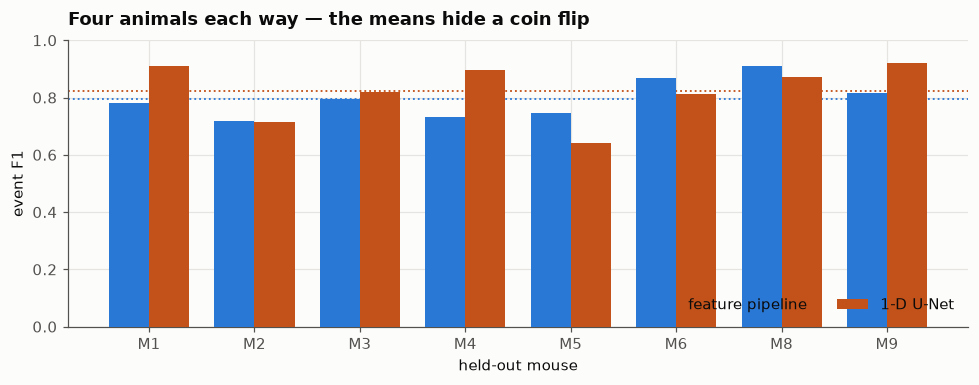

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
labels = [m.replace("train_", "") for m in per_animal["mouse"]]
xs = np.arange(len(labels))
w = 0.38

ax.bar(xs - w/2, per_animal["features"], w, color=SIG, label="feature pipeline", zorder=3)
ax.bar(xs + w/2, per_animal["unet"], w, color=EMB, label="1-D U-Net", zorder=3)
ax.axhline(mean_of(p2, "event_f1"), color=SIG, linestyle=":", linewidth=1.2)
ax.axhline(mean_of(unet, "event_f1"), color=EMB, linestyle=":", linewidth=1.2)

ax.set_xticks(xs, labels)
ax.set_xlabel("held-out mouse")
ax.set_ylabel("event F1")
ax.set_ylim(0, 1.0)
ax.set_title("Four animals each way — the means hide a coin flip", loc="left",
             fontweight="bold", pad=10)
ax.legend(frameon=False, ncol=2, loc="lower right")
plt.tight_layout()
plt.show()

## 3. Which architecture wins depends on the metric

Same folds, same animals, same post-processing and scoring code. The only difference is
where the per-sample probability came from.

In [6]:
f = p2.sort("file")
u = unet.sort("file")
assert (f["file"] == u["file"]).all()

rows = []
for metric in ("event_f1", "event_sensitivity", "event_precision",
               "false_alarms_per_hour", "sample_f1"):
    a, b = f[metric].to_numpy(), u[metric].to_numpy()
    ok = np.isfinite(a) & np.isfinite(b)
    p = stats.wilcoxon(a[ok], b[ok]).pvalue
    rows.append({
        "metric": metric,
        "features": round(a[ok].mean(), 3),
        "unet": round(b[ok].mean(), 3),
        "delta": round(b[ok].mean() - a[ok].mean(), 3),
        "paired p": round(p, 4),
        "verdict": "distinguishable" if p < 0.05 else "within noise",
    })
print(pl.DataFrame(rows))

shape: (5, 6)
┌───────────────────────┬──────────┬───────┬────────┬──────────┬─────────────────┐
│ metric                ┆ features ┆ unet  ┆ delta  ┆ paired p ┆ verdict         │
│ ---                   ┆ ---      ┆ ---   ┆ ---    ┆ ---      ┆ ---             │
│ str                   ┆ f64      ┆ f64   ┆ f64    ┆ f64      ┆ str             │
╞═══════════════════════╪══════════╪═══════╪════════╪══════════╪═════════════════╡
│ event_f1              ┆ 0.796    ┆ 0.823 ┆ 0.028  ┆ 0.2424   ┆ within noise    │
│ event_sensitivity     ┆ 0.805    ┆ 0.963 ┆ 0.158  ┆ 0.0      ┆ distinguishable │
│ event_precision       ┆ 0.828    ┆ 0.737 ┆ -0.091 ┆ 0.0      ┆ distinguishable │
│ false_alarms_per_hour ┆ 4.305    ┆ 8.205 ┆ 3.899  ┆ 0.0      ┆ distinguishable │
│ sample_f1             ┆ 0.639    ┆ 0.763 ┆ 0.124  ┆ 0.0      ┆ distinguishable │
└───────────────────────┴──────────┴───────┴────────┴──────────┴─────────────────┘


**The U-Net wins decisively at sample level and not at all at event level.**

That is not a contradiction; the two metrics answer different questions. Dense per-sample
segmentation should localise boundaries better than window classification followed by
post-hoc reconstruction, and it does. But better boundaries do not make event *counting*
better — the gain is spent trading precision for sensitivity.

The published benchmark reports sample-level scores. Following that choice would have
selected the U-Net and shipped the detector that is worse at the deliverable, as the next
figure shows.

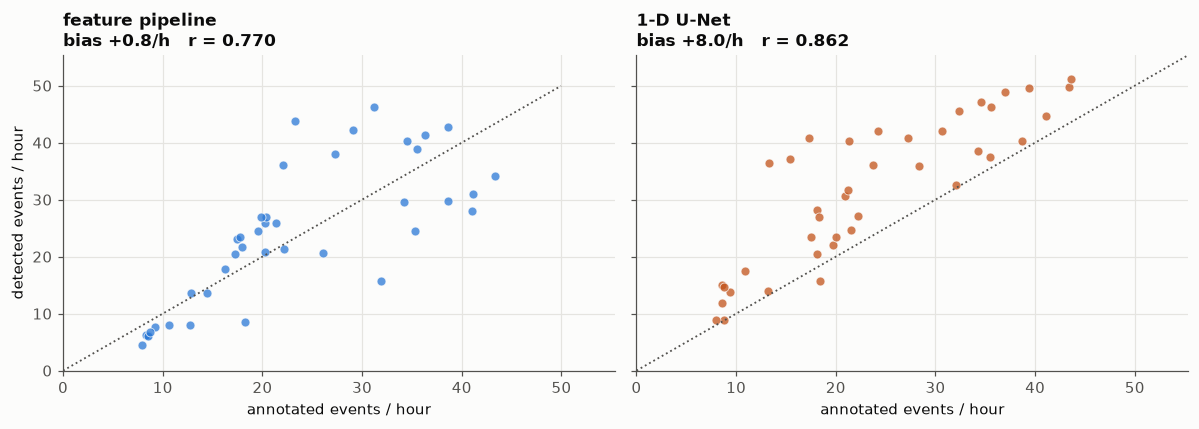

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.0), sharey=True, sharex=True)

for ax, frame, name, colour in (
    (axes[0], p2, "feature pipeline", SIG),
    (axes[1], unet, "1-D U-Net", EMB),
):
    true = frame["burden_true"].to_numpy()
    pred = frame["burden_pred"].to_numpy()
    ok = np.isfinite(true) & np.isfinite(pred)
    true, pred = true[ok], pred[ok]
    bias = (pred - true).mean()
    corr = np.corrcoef(true, pred)[0, 1]

    lim = [0, max(true.max(), pred.max()) * 1.08]
    ax.plot(lim, lim, color=MUTED, linestyle=":", linewidth=1.2)
    ax.scatter(true, pred, s=34, color=colour, alpha=0.75, edgecolor=SURFACE, linewidth=0.6)
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("annotated events / hour")
    ax.set_title(f"{name}\nbias {bias:+.1f}/h   r = {corr:.3f}", loc="left",
                 fontweight="bold", fontsize=11)

axes[0].set_ylabel("detected events / hour")
plt.tight_layout()
plt.show()

Seizure burden is the deliverable — the number a lab puts in a paper. The feature pipeline
sits on the identity line (bias +0.6/h). The U-Net tracks the *shape* of the variation
better (r = 0.862 against 0.759) while systematically **overcounting by 8 events an hour**,
because it raises nearly twice the false alarms.

A detector can have a better correlation and still be the wrong tool.

## 4. Feature ablations, with the noise floor respected

Removing one group at a time cannot distinguish "useless" from "redundant with another
group", so groups were also removed in pairs. Deltas are compared with a paired Wilcoxon
test across all 40 recordings, because the fold spread is larger than most of the effects.

In [8]:
base = p2.sort("file")["event_f1"].to_numpy()
sizes = {"spectral": 11, "wavelet": 13, "morphology": 16, "rhythmicity": 17,
         "artifact": 19, "spectral+artifact": 11, "spectral+wavelet": 7,
         "wavelet+artifact": 13}

rows = []
for path in sorted((A / "phase2").glob("results_without_*.parquet")):
    name = path.stem.replace("results_without_", "")
    v = pl.read_parquet(path).sort("file")["event_f1"].to_numpy()
    d = v - base
    ok = np.isfinite(d)
    p = stats.wilcoxon(v[ok], base[ok]).pvalue
    rows.append({"removed": name, "features left": sizes.get(name, 0),
                 "event F1": round(float(v[ok].mean()), 3),
                 "delta": round(float(d[ok].mean()), 3),
                 "paired p": round(p, 4),
                 "verdict": "distinguishable" if p < 0.05 else "within noise"})
print(pl.DataFrame(rows).sort("delta"))

shape: (8, 6)
┌───────────────────┬───────────────┬──────────┬────────┬──────────┬─────────────────┐
│ removed           ┆ features left ┆ event F1 ┆ delta  ┆ paired p ┆ verdict         │
│ ---               ┆ ---           ┆ ---      ┆ ---    ┆ ---      ┆ ---             │
│ str               ┆ i64           ┆ f64      ┆ f64    ┆ f64      ┆ str             │
╞═══════════════════╪═══════════════╪══════════╪════════╪══════════╪═════════════════╡
│ morphology        ┆ 16            ┆ 0.757    ┆ -0.038 ┆ 0.0208   ┆ distinguishable │
│ spectral+wavelet  ┆ 7             ┆ 0.766    ┆ -0.03  ┆ 0.5627   ┆ within noise    │
│ rhythmicity       ┆ 17            ┆ 0.772    ┆ -0.023 ┆ 0.0017   ┆ distinguishable │
│ wavelet           ┆ 13            ┆ 0.781    ┆ -0.014 ┆ 0.6753   ┆ within noise    │
│ wavelet+artifact  ┆ 13            ┆ 0.784    ┆ -0.012 ┆ 0.8264   ┆ within noise    │
│ spectral+artifact ┆ 11            ┆ 0.786    ┆ -0.01  ┆ 0.002    ┆ distinguishable │
│ spectral          ┆ 11     

/Users/ethanhuffington/Desktop/PROJECTS/mouse-seizure/.venv/lib/python3.13/site-packages/scipy/stats/_wilcoxon.py:192: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


**Only morphology and rhythmicity are clearly load-bearing.** Everything else sits inside
the noise on a paired test — including the large-looking `spectral+wavelet` drop, which is
driven by a handful of recordings.

Two things worth noting because they are easy to get wrong:

- The mean and the paired test **disagree in both directions**. `spectral+wavelet` has a
  large mean drop and no significance; `spectral+artifact` has a tiny mean drop that is
  highly consistent. The paired test is the trustworthy one, because the folds are paired.
- The spectral/wavelet redundancy hypothesis is **suggestive but unconfirmed**. Removing
  both cost 3.5× the additive prediction, which is the signature of redundancy, but at
  p = 0.405 it is not distinguishable from zero.

This inverts the source specification, which leads with spectral band power. The artifact
group measured as dead weight and was dropped, leaving 19 features.

## 5. What going real-time costs

The offline pipeline filters bidirectionally and smooths a trace that already contains the
whole recording. A closed-loop system can do neither. The causal variant substitutes
forward-only filtering, trailing-window probabilities, and a persistence counter.

In [9]:
causal = load("phase3/results_causal.parquet").sort("file")
rows = []
for metric in ("event_f1", "event_sensitivity", "event_precision", "false_alarms_per_hour"):
    a, b = f[metric].to_numpy(), causal[metric].to_numpy()
    ok = np.isfinite(a) & np.isfinite(b)
    p = stats.wilcoxon(a[ok], b[ok]).pvalue
    rows.append({"metric": metric, "offline": round(a[ok].mean(), 3),
                 "causal": round(b[ok].mean(), 3),
                 "delta": round(b[ok].mean() - a[ok].mean(), 3),
                 "paired p": round(p, 4),
                 "verdict": "distinguishable" if p < 0.05 else "within noise"})
print(pl.DataFrame(rows))
print()
d = causal["declaration_delay_s"].to_numpy()
print(f"declaration delay: min {d.min():.1f}s  median {np.median(d):.1f}s  max {d.max():.1f}s")

shape: (4, 6)
┌───────────────────────┬─────────┬────────┬────────┬──────────┬─────────────────┐
│ metric                ┆ offline ┆ causal ┆ delta  ┆ paired p ┆ verdict         │
│ ---                   ┆ ---     ┆ ---    ┆ ---    ┆ ---      ┆ ---             │
│ str                   ┆ f64     ┆ f64    ┆ f64    ┆ f64      ┆ str             │
╞═══════════════════════╪═════════╪════════╪════════╪══════════╪═════════════════╡
│ event_f1              ┆ 0.796   ┆ 0.786  ┆ -0.009 ┆ 0.3682   ┆ within noise    │
│ event_sensitivity     ┆ 0.805   ┆ 0.836  ┆ 0.032  ┆ 0.4512   ┆ within noise    │
│ event_precision       ┆ 0.828   ┆ 0.797  ┆ -0.031 ┆ 0.0028   ┆ distinguishable │
│ false_alarms_per_hour ┆ 4.305   ┆ 5.629  ┆ 1.324  ┆ 0.0078   ┆ distinguishable │
└───────────────────────┴─────────┴────────┴────────┴──────────┴─────────────────┘

declaration delay: min 1.0s  median 1.8s  max 3.0s


**The cost is not in detection — it is in rejection.** Event F1 falls by 0.009, which is
within noise, but sensitivity actually *rises* while precision falls and false alarms climb
from 4.3/h to 5.6/h, both distinguishable. The offline path can see how a candidate
resolves before committing; a persistence counter can only wait a fixed number of steps.

Two latency numbers matter and they are not the same:

- **Onset localisation error** — how accurate the reported boundary is: median 0.00 s,
  IQR −0.50 to +1.00 s over 18,441 matched events. Quantised to the 0.5 s stride.
- **Declaration delay** — how long before the system *knows*, which is what a closed-loop
  device budgets for: 1.0–3.0 s, median 1.8 s, set by the persistence counter.

Onsets are reported where evidence began rather than where the counter fired, so the
declaration delay is carried separately instead of being hidden inside the onset.

## 6. The held-out test split, and where the feature pipeline broke

Ten mice that no training script ever loaded. Both models trained on all eight training
animals; thresholds fixed at the median of the eight cross-validation folds before running.
Evaluated once.

In [10]:
test = load("phase3/results_testsplit.parquet")
rows = []
for model in ("features", "unet"):
    sub = test.filter(pl.col("model") == model)
    rows.append({
        "model": model,
        "event F1": round(mean_of(sub, "event_f1"), 3),
        "sensitivity": round(mean_of(sub, "event_sensitivity"), 3),
        "precision": round(mean_of(sub, "event_precision"), 3),
        "false alarms/h": round(mean_of(sub, "false_alarms_per_hour"), 1),
        "sample F1": round(mean_of(sub, "sample_f1"), 3),
    })
print(pl.DataFrame(rows))
print("\npublished AugUNet1D (sample level): precision 0.91  recall 0.90")
print("published Twin Peaks  (sample level): precision 0.67  recall 0.81")
print(f"ours, U-Net          (sample level): precision "
      f"{mean_of(test.filter(pl.col('model') == 'unet'), 'sample_precision'):.3f}  "
      f"recall {mean_of(test.filter(pl.col('model') == 'unet'), 'sample_sensitivity'):.3f}")

shape: (2, 6)
┌──────────┬──────────┬─────────────┬───────────┬────────────────┬───────────┐
│ model    ┆ event F1 ┆ sensitivity ┆ precision ┆ false alarms/h ┆ sample F1 │
│ ---      ┆ ---      ┆ ---         ┆ ---       ┆ ---            ┆ ---       │
│ str      ┆ f64      ┆ f64         ┆ f64       ┆ f64            ┆ f64       │
╞══════════╪══════════╪═════════════╪═══════════╪════════════════╪═══════════╡
│ features ┆ 0.622    ┆ 0.949       ┆ 0.485     ┆ 36.3           ┆ 0.668     │
│ unet     ┆ 0.912    ┆ 0.992       ┆ 0.847     ┆ 5.4            ┆ 0.89      │
└──────────┴──────────┴─────────────┴───────────┴────────────────┴───────────┘

published AugUNet1D (sample level): precision 0.91  recall 0.90
published Twin Peaks  (sample level): precision 0.67  recall 0.81
ours, U-Net          (sample level): precision 0.838  recall 0.955


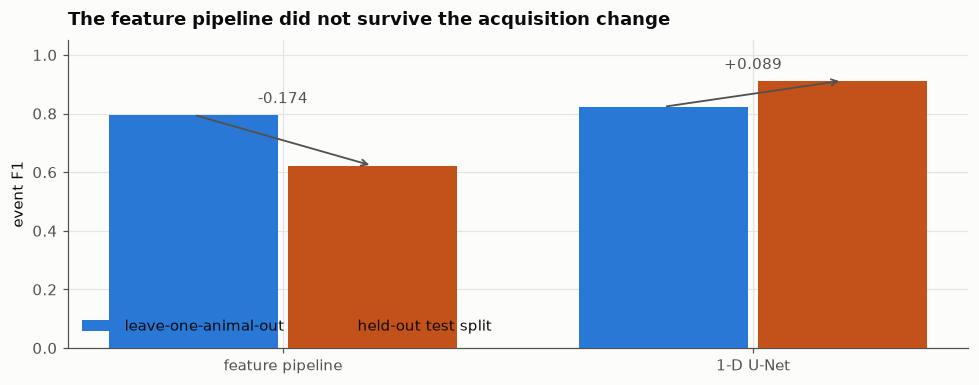

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.6))
loao = {"features": mean_of(p2, "event_f1"), "unet": mean_of(unet, "event_f1")}
held = {r["model"]: r["event F1"] for r in rows}
xs = np.arange(2)

ax.bar(xs - 0.19, [loao["features"], loao["unet"]], 0.36, color=SIG,
       label="leave-one-animal-out", zorder=3)
ax.bar(xs + 0.19, [held["features"], held["unet"]], 0.36, color=EMB,
       label="held-out test split", zorder=3)
for i, model in enumerate(("features", "unet")):
    ax.annotate("", xy=(i + 0.19, held[model]), xytext=(i - 0.19, loao[model]),
                arrowprops=dict(arrowstyle="->", color=MUTED, linewidth=1.2))
    ax.text(i, max(loao[model], held[model]) + 0.04,
            f"{held[model] - loao[model]:+.3f}", ha="center", color=MUTED, fontsize=10)

ax.set_xticks(xs, ["feature pipeline", "1-D U-Net"])
ax.set_ylabel("event F1")
ax.set_ylim(0, 1.05)
ax.set_title("The feature pipeline did not survive the acquisition change", loc="left",
             fontweight="bold", pad=10)
ax.legend(frameon=False, ncol=2, loc="lower left")
plt.tight_layout()
plt.show()

The feature pipeline fell from 0.796 to 0.622 while the U-Net *rose* from 0.823 to 0.912.

Sensitivity held at 0.949, so the feature model still finds the seizures — precision
collapsed to 0.485. That is a transfer failure, not a detection failure, which is
diagnosable.

In [12]:
from mouse_seizure.dataset import cached
from mouse_seizure.features import FEATURE_GROUPS, FEATURE_NAMES
from mouse_seizure.io import find_recordings, parse_name

cols = [c for c in FEATURE_NAMES if c not in FEATURE_GROUPS["artifact"]]

def baseline_pool(split, n=6):
    paths = [p for p in find_recordings() if parse_name(p.stem)[1] == split][:n]
    frame = pl.concat([cached(p).select(cols + ["label_fraction"]) for p in paths])
    return frame.filter(pl.col("label_fraction") == 0).select(cols).to_numpy()

train_base, test_base = baseline_pool("train"), baseline_pool("test")
shift = np.array([
    (test_base[:, i].mean() - train_base[:, i].mean()) / (train_base[:, i].std() + 1e-12)
    for i in range(len(cols))
])
order = np.argsort(-np.abs(shift))
for i in order[:5]:
    print(f"{cols[i]:22s} train {train_base[:, i].mean():8.4f}   "
          f"test {test_base[:, i].mean():8.4f}   {shift[i]:+6.1f} SD")
print(f"\nmedian |shift| across {len(cols)} features: {np.median(np.abs(shift)):.2f} SD")

harmonic_ratio         train   0.2710   test   3.8960    +16.6 SD
rel_high               train   0.0181   test   0.1468     +8.2 SD
wavelet_l4             train   0.0095   test   0.0899     +7.6 SD
wavelet_l3             train   0.0693   test   0.1646     +3.1 SD
wavelet_entropy        train   0.5086   test   0.7192     +2.5 SD

median |shift| across 19 features: 0.93 SD


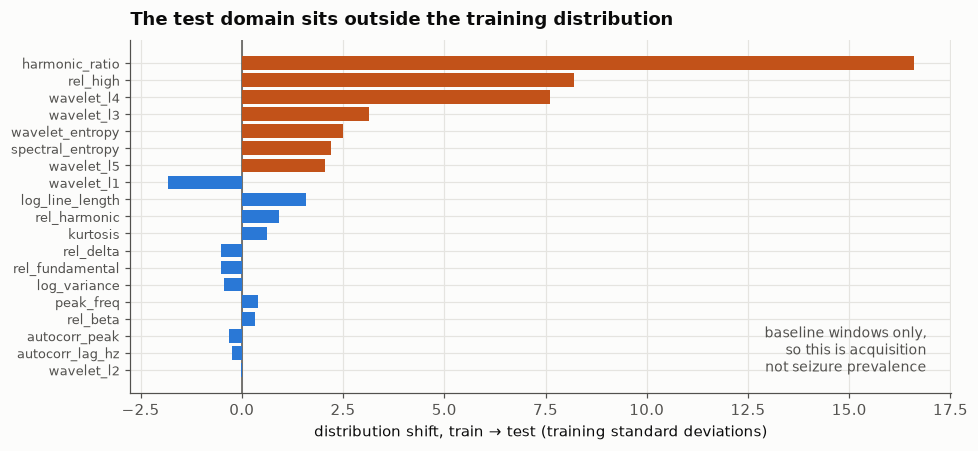

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.2))
idx = order[::-1]
colours = [EMB if abs(shift[i]) > 2 else SIG for i in idx]
ax.barh(np.arange(len(idx)), [shift[i] for i in idx], color=colours, zorder=3)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(np.arange(len(idx)), [cols[i] for i in idx], fontsize=8.5)
ax.set_xlabel("distribution shift, train → test (training standard deviations)")
ax.set_title("The test domain sits outside the training distribution", loc="left",
             fontweight="bold", pad=10)
ax.text(0.97, 0.06, "baseline windows only,\nso this is acquisition\nnot seizure prevalence",
        transform=ax.transAxes, ha="right", color=MUTED, fontsize=9)
plt.tight_layout()
plt.show()

**Cause.** Training data was acquired at 1000 Hz — oversampled, so its 30–100 Hz band is
clean — then decimated to 400 Hz. Test data was acquired natively at 400 Hz, where a weaker
acquisition-side anti-alias filter folds content above 200 Hz down into that band. Every
feature built on high-frequency ratios is therefore reading a different signal.

The 1–100 Hz band-pass applied to both splits equalises *bandwidth*, but aliasing that
happened inside the amplifier cannot be undone afterwards. The mitigation designed in
Phase 0 was insufficient, and this is by how much.

The U-Net saw the same shift and barely noticed, presumably because it learned
low-frequency waveform morphology rather than band ratios.

**A plausible fix — low-pass both splits below the contaminated band and drop the two
worst-shifted features — is deliberately left untested.** Validating it would mean a second
look at a split that has been spent, and a number that improves after you look at it is not
a held-out number.

## Summary

| | leave-one-animal-out | held-out test split |
|---|---|---|
| feature pipeline | **0.796** F1, 4.3 FA/h | 0.622 F1, 36.3 FA/h |
| 1-D U-Net | 0.823 F1, 8.2 FA/h | **0.912** F1, 5.4 FA/h |
| causal / real-time | 0.786 F1, 1.8 s declaration delay | — |

The feature pipeline is the better instrument in-domain — lower false alarms, near-unbiased
burden — and the U-Net is the more robust one across an acquisition change. Neither
conclusion is visible from a single number, which is the argument for reporting several.